<a href="https://colab.research.google.com/github/nab9644-boop/Reinforcement_Learning_OP/blob/main/HW3/HW3RL_Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tol = 1e-8
max_iter = 10000
al1 = 0.25
al2 = 1e-3

In [3]:
def f1(z):
  x = z[0]
  return - np.exp(-(x-1)**2)

def grad1(z):
  x = z[0]
  return np.array([2*(x-1)*np.exp(-(x-1)**2)])

def hess1(z):
  x = z[0]
  return np.array([[2*np.exp(-(x-1)**2) - (2*x-2)**2 * np.exp(-(x-1)**2)]])

x0_1 = np.array([0.0])
xstar1 = np.array([1.0])



In [4]:
def f2(z):
   x, y = z[0], z[1]
   return (1-x)**2 + 100*(y-x**2)**2

def grad2(z):
  x, y = z[0], z[1]
  return np.array([-2+2*x -400*x*(y - x**2), 200*(y-x**2)])

def hess2(z):
  x, y = z[0], z[1]
  return np.array([[2 - 400*y + 1200*x**2, -400*x],
           [-400*x, 200]])

x0_2 = np.array([1.2, 1.2])
xstar2 = np.array([1.0, 1.0])

In [5]:
A3 = np.array([[3.0, 1.0],
              [1.0, 3.0]])
b3 = np.array([-1.0, 1.0])

def f3(z):
  return 0.5 * z @ A3 @ z + b3 @ z

def grad3(z):
  return A3 @ z + b3

def hess3(z):
  return A3

x0_3= np.array([10.0, 10.0])
xstar3 = np.array([0.5, -0.5])


In [6]:
A4 = np.array([[1.0, 1.0, 0.0],
              [1.0, 1.0, 0.0],
               [0.0, 0.0, 4.0]])
b4 = np.array([0.0, 0.0, 1.0])

def f4(z):
  return 0.5 * z @ A4 @ z - b4 @ z

def grad4(z):
  return A4 @ z - b4

def hess4(z):
  return A4

x0_4= np.array([-10.0, -10.0, -10.0])
xstar4 = np.array([0.0, 0.0, 1/4])


In [7]:
def gradient_descent(f, df, x0, al, tol, max_iter):
  x = np.array(x0, dtype=float)
  history = [x.copy()]
  for k in range(max_iter):
    x = x - al * df(x)
    history.append(x.copy())
    if np.linalg.norm(df(x)) < tol:
      return x, k + 1, True, history

  return x, max_iter, False, history

np.linalg.eigvalsh(A3)



array([2., 4.])

In [8]:
def backtracking_ls(f, x, p, g, c1, rho):
  al = 1.0
  current_f = f(x)
  directional_derivative = g @ p

  while f(x + al * p) > current_f + c1 * al * directional_derivative and al > 1e-10:
    al = rho * al

  return al

In [9]:
def gd_backtracking(f, df, x0, c1, rho, tol, max_iter):
  x = np.array(x0, dtype=float)
  history = [x.copy()]
  alphas = []
  for k in range(max_iter):
    g = df(x)
    p = -g
    alpha = backtracking_ls(f, x, p, g, c1, rho)
    x = x + alpha * p
    history.append(x.copy())
    alphas.append(alpha)

    if np.linalg.norm(df(x)) < tol:
      return x, k + 1, True, history, alphas

  return x, max_iter, False, history, alphas


In [10]:
def newton_backtracking(f, df, d2f, x0, c1, rho, tau, tol, max_iter):
  x = np.array(x0, dtype=float)
  history = [x.copy()]
  alphas = []
  for k in range(max_iter):
    g = df(x)
    H = d2f(x)
    lam_min = np.linalg.eigvalsh(H).min()
    if lam_min <= 0:
      H = H + (tau - lam_min) * np.eye(H.shape[0])
    p = np.linalg.solve(H, -g)
    alpha = backtracking_ls(f, x, p, g, c1, rho)
    x = x + alpha * p
    history.append(x.copy())
    alphas.append(alpha)

    if np.linalg.norm(df(x)) < tol:
      return x, k + 1, True, history, alphas

  return x, max_iter, False, history, alphas


In [11]:
def gaussian_smoothing(f, x0, al, sig, M, tol, max_iter):
  x = np.array(x0, dtype=float)
  history = [x.copy()]
  n = len(x)
  for k in range(max_iter):
    f_x = f(x)
    g_sum = np.zeros(n)

    E = np.random.randn(M, n)
    for eps in E:
      g_sum = g_sum + (f(x +sig*eps) - f_x)*eps
    g_hat = g_sum/(M *sig)

    x = x - al * g_hat
    history.append(x.copy())
    if np.linalg.norm(g_hat) < tol:
      return x, k + 1, True, history

  return x, max_iter, False, history



In [12]:
def distances(hist, xstar):
    H = np.array(hist)
    return np.linalg.norm(H - xstar, axis=1)

In [13]:
# Gradient descent part 1
x_final, n_iter, converged, hist_gd1 = gradient_descent(f1, grad1, x0_1, al1, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f1(x_final):.6e} | iters = {n_iter} | converged = {converged}")
#Gradient descent w backtracking
x_final, n_iter, converged, hist_bt1, alphas_bt1 = gd_backtracking(f1, grad1, x0_1, 1e-4, 0.5, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f1(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_bt1}")
# Newton
x_final, n_iter, converged, hist_nt1, alphas_nt1 = newton_backtracking(f1, grad1, hess1, x0_1, 1e-4, 0.5, 1e-4, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f1(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_nt1}")
#Gaussian
np.random.seed(0)
x_final, n_iter, converged, hist_gs1 = gaussian_smoothing(f1, x0_1, al1, 0.01, 50, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f1(x_final):.6e} | iters = {n_iter} | converged = {converged}")

x* = [1.] | f(x*) = -1.000000e+00 | iters = 30 | converged = True
x* = [1.] | f(x*) = -1.000000e+00 | iters = 2496 | converged = True | alphas = [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0,

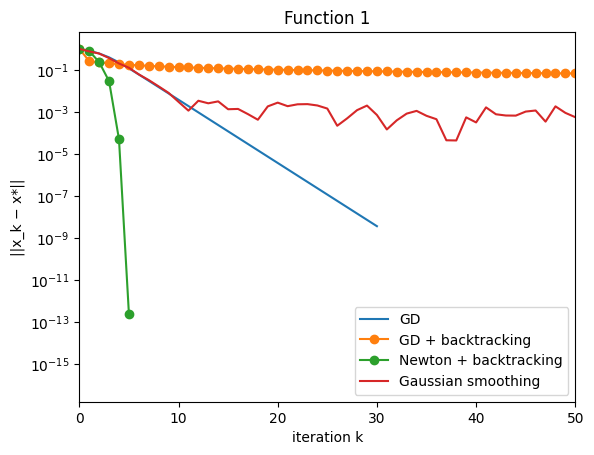

In [14]:
# norm Plots for f3
dist_gd1 = distances(hist_gd1, xstar1)
dist_bt1 = distances(hist_bt1, xstar1)
dist_nt1 = distances(hist_nt1, xstar1)
dist_gs1 = distances(hist_gs1, xstar1)

plt.figure()
plt.semilogy(dist_gd1, label="GD")
plt.semilogy(np.maximum(dist_bt1, 1e-16), marker="o", label="GD + backtracking")
plt.semilogy(np.maximum(dist_nt1, 1e-16), marker="o", label="Newton + backtracking")
plt.semilogy(dist_gs1, label="Gaussian smoothing")
plt.title("Function 1") ; plt.xlim(0, 50)
plt.xlabel("iteration k"); plt.ylabel("||x_k − x*||")
plt.legend(); plt.show()

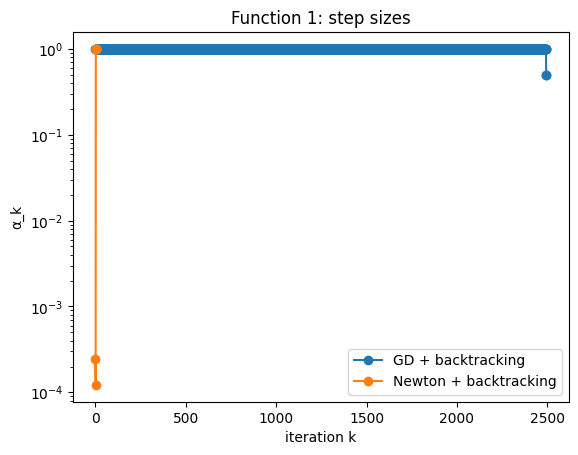

In [15]:
#alpha plots for f1
plt.figure()
plt.semilogy(alphas_bt1, marker="o", label="GD + backtracking")
plt.semilogy(alphas_nt1, marker="o", label="Newton + backtracking")
plt.title("Function 1: step sizes")
plt.xlabel("iteration k"); plt.ylabel("α_k")
plt.legend(); plt.show()

In [16]:
# Gradient descent part 2
x_final, n_iter, converged, hist_gd2 = gradient_descent(f2, grad2, x0_2, al2, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f2(x_final):.6e} | iters = {n_iter} | converged = {converged}")
#Gradient descent w backtracking
x_final, n_iter, converged, hist_bt2, alphas_bt2 = gd_backtracking(f2, grad2, x0_2, 1e-4, 0.5, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f2(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_bt2}")
#Newton
x_final, n_iter, converged, hist_nt2, alphas_nt2 = newton_backtracking(f2, grad2, hess2, x0_2, 1e-4, 0.5, 1e-4, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f2(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_nt2}")
#Gaussian
np.random.seed(0)
x_final, n_iter, converged, hist_gs2 = gaussian_smoothing(f2, x0_2, al1, 0.01, 50, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f2(x_final):.6e} | iters = {n_iter} | converged = {converged}")

x* = [1.0024539  1.00492363] | f(x*) = 6.031238e-06 | iters = 10000 | converged = False
x* = [1.00000904 1.00001808] | f(x*) = 8.180337e-11 | iters = 10000 | converged = False | alphas = [0.0009765625, 0.0009765625, 0.0009765625, 0.0009765625, 0.001953125, 0.001953125, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.0009765625, 0.0078125, 0.0009765625, 0.00390625, 0.001953125, 0.0009765625, 0.0078125, 0.

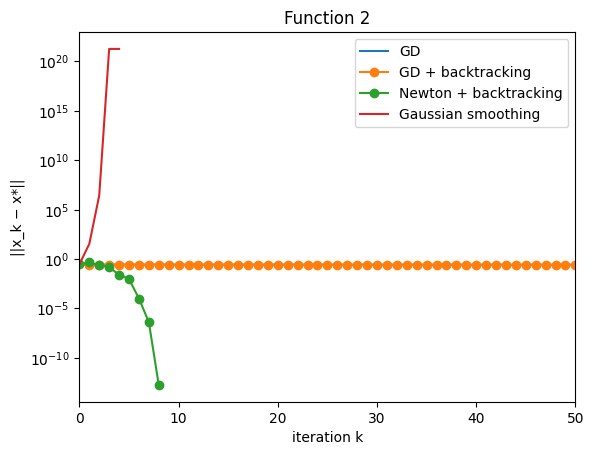

In [17]:
# norm Plots for f2
dist_gd2 = distances(hist_gd2, xstar2)
dist_bt2 = distances(hist_bt2, xstar2)
dist_nt2 = distances(hist_nt2, xstar2)
dist_gs2 = distances(hist_gs2, xstar2)

plt.figure()
plt.semilogy(dist_gd2, label="GD")
plt.semilogy(np.maximum(dist_bt2, 1e-16), marker="o", label="GD + backtracking")
plt.semilogy(np.maximum(dist_nt2, 1e-16), marker="o", label="Newton + backtracking")
plt.semilogy(dist_gs2, label="Gaussian smoothing")
plt.title("Function 2") ; plt.xlim(0, 50)
plt.xlabel("iteration k"); plt.ylabel("||x_k − x*||")
plt.legend(); plt.show()

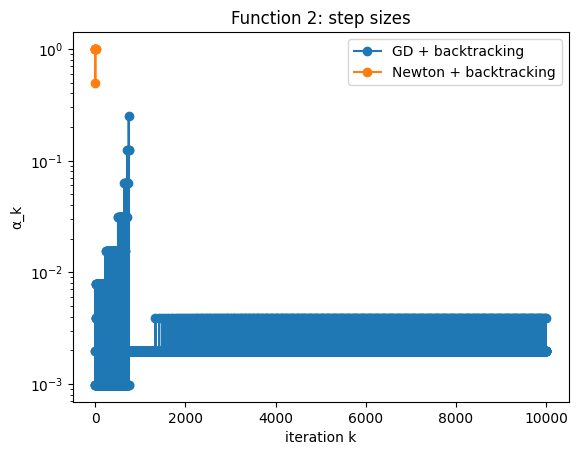

In [18]:
#alpha plots for f4
plt.figure()
plt.semilogy(alphas_bt2, marker="o", label="GD + backtracking")
plt.semilogy(alphas_nt2, marker="o", label="Newton + backtracking")
plt.title("Function 2: step sizes")
plt.xlabel("iteration k"); plt.ylabel("α_k")
plt.legend(); plt.show()

In [19]:
# Gradient descent part 3
x_final, n_iter, converged, hist_gd3 = gradient_descent(f3, grad3, x0_3, al1, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f3(x_final):.6e} | iters = {n_iter} | converged = {converged}")
#Gradient descent w backtracking
x_final, n_iter, converged, hist_bt3, alphas_bt3 = gd_backtracking(f3, grad3, x0_3, 1e-4, 0.5, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f3(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_bt3}")
# Newton
x_final, n_iter, converged, hist_nt3, alphas_nt3 = newton_backtracking(f3, grad3, hess3, x0_3, 1e-4, 0.5, 1e-4, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f3(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_nt3}")
#Gaussian smoothing
np.random.seed(0)
x_final, n_iter, converged, hist_gs3 = gaussian_smoothing(f3, x0_3, 0.25, 0.01, 50, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f3(x_final):.6e} | iters = {n_iter} | converged = {converged}")

x* = [ 0.5 -0.5] | f(x*) = -5.000000e-01 | iters = 28 | converged = True
x* = [ 0.5 -0.5] | f(x*) = -5.000000e-01 | iters = 2 | converged = True | alphas = [0.5, 0.25]
x* = [ 0.5 -0.5] | f(x*) = -5.000000e-01 | iters = 1 | converged = True | alphas = [1.0]
x* = [ 0.49390283 -0.49849046] | f(x*) = -4.999500e-01 | iters = 10000 | converged = False


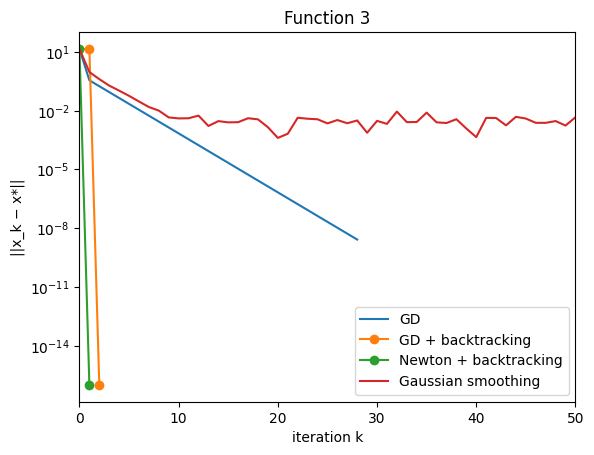

In [20]:
# norm Plots for f3
dist_gd3 = distances(hist_gd3, xstar3)
dist_bt3 = distances(hist_bt3, xstar3)
dist_nt3 = distances(hist_nt3, xstar3)
dist_gs3 = distances(hist_gs3, xstar3)

plt.figure()
plt.semilogy(dist_gd3, label="GD")
plt.semilogy(np.maximum(dist_bt3, 1e-16), marker="o", label="GD + backtracking")
plt.semilogy(np.maximum(dist_nt3, 1e-16), marker="o", label="Newton + backtracking")
plt.semilogy(dist_gs3, label="Gaussian smoothing")
plt.title("Function 3") ; plt.xlim(0, 50)
plt.xlabel("iteration k"); plt.ylabel("||x_k − x*||")
plt.legend(); plt.show()

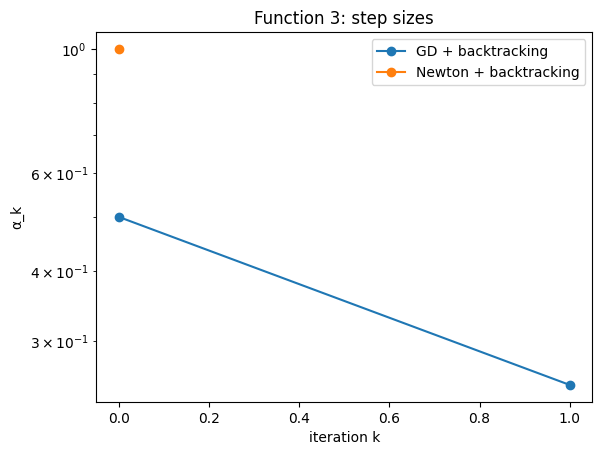

In [21]:
#alpha plots for f3
plt.figure()
plt.semilogy(alphas_bt3, marker="o", label="GD + backtracking")
plt.semilogy(alphas_nt3, marker="o", label="Newton + backtracking")
plt.title("Function 3: step sizes")
plt.xlabel("iteration k"); plt.ylabel("α_k")
plt.legend(); plt.show()

In [22]:
# Gradient descent part 4
x_final, n_iter, converged, hist_gd4 = gradient_descent(f4, grad4, x0_4, al1, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f4(x_final):.6e} | iters = {n_iter} | converged = {converged}")
#Gradient descent w backtracking
x_final, n_iter, converged, hist_bt4, alphas_bt4 = gd_backtracking(f4, grad4, x0_4, 1e-4, 0.5, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f4(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_bt4}")
#Newton
x_final, n_iter, converged, hist_nt4, alphas_nt4 = newton_backtracking(f4, grad4, hess4, x0_4, 1e-4, 0.5, 1e-4, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f4(x_final):.6e} | iters = {n_iter} | converged = {converged} | alphas = {alphas_nt4}")
#Gaussian
np.random.seed(0)
x_final, n_iter, converged, hist_gs4 = gaussian_smoothing(f4, x0_4, al1, 0.01, 50, tol, max_iter)
print(f"x* = {x_final} | f(x*) = {f4(x_final):.6e} | iters = {n_iter} | converged = {converged}")

x* = [-2.32830644e-09 -2.32830644e-09  2.50000000e-01] | f(x*) = -1.250000e-01 | iters = 32 | converged = True
x* = [0.   0.   0.25] | f(x*) = -1.250000e-01 | iters = 2 | converged = True | alphas = [0.5, 0.25]
x* = [-2.63081521e-12  1.31190177e-13  2.50000000e-01] | f(x*) = -1.250000e-01 | iters = 3 | converged = True | alphas = [1.0, 1.0, 1.0]
x* = [ 0.51259172 -0.51049443  0.25274692] | f(x*) = -1.249827e-01 | iters = 10000 | converged = False


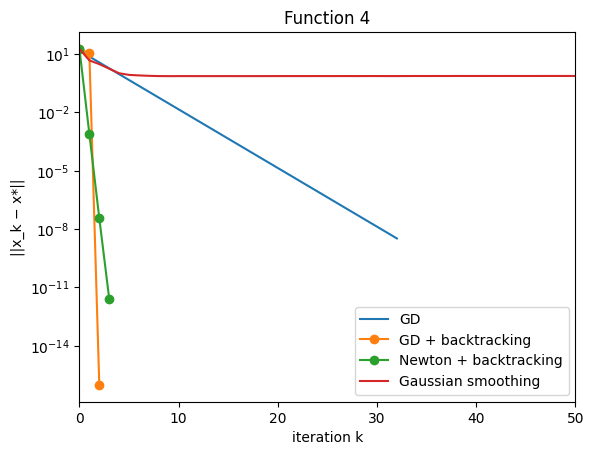

In [23]:
# norm Plots for f3
dist_gd4 = distances(hist_gd4, xstar4)
dist_bt4 = distances(hist_bt4, xstar4)
dist_nt4 = distances(hist_nt4, xstar4)
dist_gs4 = distances(hist_gs4, xstar4)

plt.figure()
plt.semilogy(dist_gd4, label="GD")
plt.semilogy(np.maximum(dist_bt4, 1e-16), marker="o", label="GD + backtracking")
plt.semilogy(np.maximum(dist_nt4, 1e-16), marker="o", label="Newton + backtracking")
plt.semilogy(dist_gs4, label="Gaussian smoothing")
plt.title("Function 4") ; plt.xlim(0, 50)
plt.xlabel("iteration k"); plt.ylabel("||x_k − x*||")
plt.legend(); plt.show()

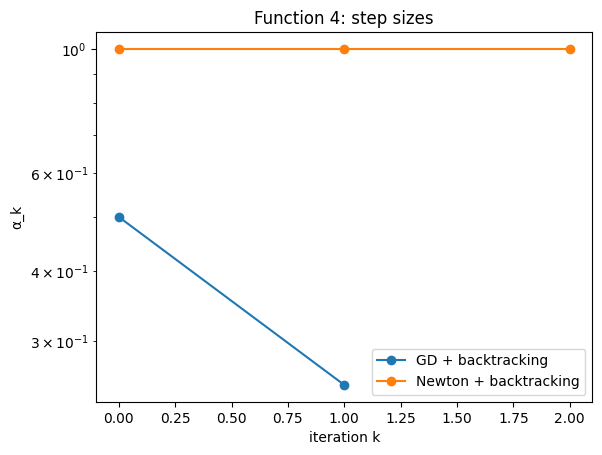

In [24]:
#alpha plots for f4
plt.figure()
plt.semilogy(alphas_bt4, marker="o", label="GD + backtracking")
plt.semilogy(alphas_nt4, marker="o", label="Newton + backtracking")
plt.title("Function 4: step sizes")
plt.xlabel("iteration k"); plt.ylabel("α_k")
plt.legend(); plt.show()